# Part B: Flow Matching from Scratch!
Student notebook: implement the marked exercises using [the assignment](partb.html).


**Conventions:** MNIST pixels are in $[0,1]$. Flow time goes from Gaussian noise
at 0 to data at 1. Predict velocity $x_1-x_0$, not noise. Part B uses
$v_u+\gamma(v_c-v_u)$ with $\gamma=5$; this is different from Part A's guidance convention.

## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [1]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'partb'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('UEsDBBQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAY29sYWJfc2V0dXAucHm1V11T3DYUfd9foZIH2YkRENI23Yk7QwlJmBSyA6QvDOPR2nd3VWzJleSFLcN/75VkG8MCaTPTfVivdaVzv8/VbmxsHFxD3lgoyHRFpLIwVeqSGLBNTfjMgibG8rmQc2IXQExT10pbMm1kUQIpVc7LcsU2NjZGovKS8CjFlFVgecEt7yTKjGZaVaTmdoHydieZ4Gu3xTTTWqscjOlXVmY0yjSgEdri869GaLQ1JecXo9GogBkREmVlmVXCGDQzuuISvYnHI4IfNOwwyMlMaGMT54UkDgchCSctMlGyXJGZ0ugSL1BBzfNLPgeD+7kl+YLLORTeTwc7L9WUl2TNLi8Us3VBsMZ9NBcGyEkjrajgQGulIzrplF2BBtLUGDU0QUhULgxpI8LISWurS8S+KvkU04Q+K0loD//Ih04BHQN0VTdSukz67I4JfUUTQtmfSshozeI49phtxpx9eJKZGnIxE6BNl77TbuUUrD/R5iHFBHkAjGkbzMSddm6FFDFhoTJRfBcbq1djskRw9CldLyTWiqIWL+4PwnUO9WO1x9rQHiv7QWHN+oDf6ThWEnoQzFu7TjDqTkTQ9m4JW8OZPnQ3cv7E485jxusaZNFZ98pLu4pwx9t9g1rAPGjpX1+QQ5mXTQEYBC6NsGIJpAAHCDIXWBsRsDkjVl2CFH+jUXHiQRupoQz14r3HH5UqmhIM88ChnjOtlDXpjeQVYBJLYSPKaHy+feET5Jadd9htrD1960+H0klvbvtcBnHS9weeeiTsnTgrhLFaTBuLMcRcr+ccYxMguwgPDR6TXGGjyOYuS4N6crs7ReN7HeALKdh+3u64+E8F9T1FVXOkLXew1kJifFvicQ3X81Zvruu8vvnawmhb7o4EWb6A/DJzHBudu9yA52o+xQTQzYomtBY1frcUiL82N1ERWJq8bDEv2grsnRByyUvhGAZxER+TsdanqvTsEwL4RJtKuPpfW9ThP2xPXCM/pATNG69T7IP2i7+Ti9uscVewWH1VXQL2VIITzxMv7uelBl6sNh9OinZIjJ9n42c59xV9juWVzCH5BteH8dbIboLPuZCMnC2gm5NDi68EzsWpmwyNwQDSuB2p2HQzMW80YDA1zsxuxA75KP3ASwNtVbhmTd0gZ/lV0RaUry6/GCmsXLkUWkmGZqEG3pTYIPunO2+3s/29/U8H2fvDE5ogVUQOaosyf5rG8QCLVZeF0M4kkMhlZ7qBBK6RXzJ16d/C3ieUffqQffpydBCUeLwtumjmbqrNeO5UPXc6mDo5+XI0OQsW3wPCfq1qm0E1haJARPOv4M5O9g6PH0HDCSDcnP4GyORw8jB4nTnICnHfAI9l764HXpDPAHWoNGrI/tf3e5uu7LEBkGZw3uh8seW/lyLMxmGDINHx3LIeLUz29IZW3Nalco1Ox/TXdJf9nLx7gwQ1wZJTV37tF/aa3g7b2xVbmlL34PQ+obc3hnA1im6oH5LIThXSDYKl6Rv24w7bRQWDnG4umqkXbrPdn1BZQkFIVRuvfZu9Td7t0Ns7hnriIjngzxCNtYUQmOGk98ssbwrOhMn4kovSkfaQRB/jnlMoIXe30o+Tr4TnOb5qjliOjAMV4O/PfD5H/u8usn2vu/Z1wFiLtUkHFszBYu6XIofMyUBbLIBoOx7OKlSII8kfZe4ykNA/TvaOyEfxGy5rR8tREFqFMcoqqJRebb1++XJ3O9mJ70FNVmdON54LNmRZOxOyLKGDeHUbwttw2z24391fjEAAeMI/+8p+omA6QxyL7uEb3ti8QjJDyra7r0lk4doS7ARV4P8bLt3dyd0n8CICZdwFMtzOgurRP1BLAQIUAxQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAAAAAAAAAAACAAQAAAABjb2xhYl9zZXR1cC5weVBLBQYAAAAAAQABADwAAACMBQAAAAA=')
assert hashlib.sha256(_support).hexdigest() == 'ba2fae2d7267a416d94cd581fd0ac5eadf93d641618063a782d0dffdc36d31cd', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

GPU: Tesla T4 VRAM GiB: 14.6
PyTorch: 2.11.0+cu128 torchvision: 0.26.0+cu128
Local cache: /kaggle/working/.cache
Setup complete. Continue with the notebook below.


## Setup environment

In [1]:
# Install requirements-partb.txt in the active environment before running.
# No automatic package changes to an existing GPU environment.
import sys
assert sys.version_info >= (3,9), 'Use Python 3.9 or newer.'

In [2]:
import os, json, time, random
from pathlib import Path
from typing import Optional
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

SEED = 180
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
GROUP = os.environ.get('PARTB_GROUP','all')
assert GROUP in ('all','denoise','time','class','no_scheduler')
OUT = Path('results/partb') / GROUP
OUT.mkdir(parents=True, exist_ok=True)
metrics = {'seed':SEED,'group':GROUP,'torch':torch.__version__,
           'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
           'visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES'),
           'precision':'float32 with TF32 convolution/matmul enabled'}
print(metrics)
train_dataset = MNIST('data', train=True, download=True, transform=ToTensor())
test_dataset = MNIST('data', train=False, download=True, transform=ToTensor())
assert len(train_dataset)==60000 and len(test_dataset)==10000

def show_grid(images, title, filename, nrow=10):
    images = images.detach().float().cpu()
    grid = make_grid(images.clamp(0, 1), nrow=nrow, padding=2)
    fig, ax = plt.subplots(figsize=(12, max(2, len(images)/nrow*1.15)))
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


def loss_plot(losses, name):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(losses, alpha=.4, linewidth=.5)
    window = min(100, len(losses))
    smooth = torch.tensor(losses).unfold(0, window, 1).mean(1)
    ax.plot(range(window-1, len(losses)), smooth, linewidth=1)
    ax.set(xlabel='Optimizer step', ylabel='Mean squared error', title=name)
    fig.tight_layout(); fig.savefig(OUT / (name+'_loss.png'), dpi=120)
    plt.show(); plt.close(fig)


def make_loader(batch_size, seed=180):
    # Decode/normalize once; augmentation noise is still drawn fresh in each step.
    dataset = torch.utils.data.TensorDataset(train_dataset.data[:, None].float()/255,
                                             train_dataset.targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      pin_memory=device.type == 'cuda',
                      generator=torch.Generator().manual_seed(seed))

{'seed': 180, 'group': 'all', 'torch': '2.11.0+cpu', 'device': 'cpu', 'gpu': None, 'visible_devices': None, 'precision': 'float32 with TF32 convolution/matmul enabled'}


100%|██████████| 9.91M/9.91M [00:00<00:00, 28.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.10MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 8.93MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.58MB/s]


In [8]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


## Neural Network Resources

In this part, you will build and train a [UNet](https://arxiv.org/abs/1505.04597), which is more complex than the MLP you implemented in the NeRF project.  We provide all class definitions you may need (but feel free to add or modify them as necessary).  

Instead of asking ChatGPT to write everything for you, please consult the following resources when you get stuck — they will help you understand how and why things work under the hood.

- PyTorch Documentation — [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and [`AvgPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).
- PyTorch Documentation - [`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), the dataset we gonna use, and [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html), the off-the-shell dataloader we can directly use.
- PyTorch [tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) on how to train a classifier on CIFAR10 dataset. The structure of your training code will be very similar to this one.

# Part 1: Training a Single-step Denoising UNet


# Part 1.1: Implementing the UNet

## Implementing Simple and Composed Ops

In [11]:
class Conv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride=1, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class DownConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride=2, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class UpConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(
            nn.ConvTranspose2d(in_channels, out_channels, 4, stride=2, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class Flatten(nn.Module):
    def __init__(self):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(
            nn.AvgPool2d(7),
            nn.GELU()
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class Unflatten(nn.Module):
    def __init__(self, in_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(
            nn.ConvTranspose2d(in_channels, in_channels, 7, stride=7),
            nn.BatchNorm2d(in_channels),
            nn.GELU()
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(
            Conv(in_channels, out_channels),
            Conv(out_channels, out_channels)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class DownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(
            DownConv(in_channels, out_channels),
            ConvBlock(out_channels, out_channels)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class UpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(
            UpConv(in_channels, out_channels),
            ConvBlock(out_channels, out_channels)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====

## Implementing Unconditional UNet

In [38]:
class UnconditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        D = num_hiddens
        self.conv = ConvBlock(in_channels, D)
        self.down1, self.down2 = DownBlock(D, D), DownBlock(D, 2 * D)
        self.flatten, self.unflatten = Flatten(), Unflatten(2 * D)
        self.up1, self.up2 = UpBlock(4 * D, D), UpBlock(2 * D, D)
        self.out_block = ConvBlock(2 * D, D)
        self.out = nn.Conv2d(D, in_channels, 3, stride=1, padding=1)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        s0 = self.conv(x)
        s1 = self.down1(s0)
        s2 = self.down2(s1)
        h = self.unflatten(self.flatten(s2))
        h = self.up1(torch.cat((h,s2), dim=1))
        h = self.up2(torch.cat((h,s1), dim=1))
        o = self.out_block(torch.cat((h, s0), dim=1))
        return self.out(o)
        # ===== end of code ====

# Part 1.2: Using the UNet to Train a Denoiser

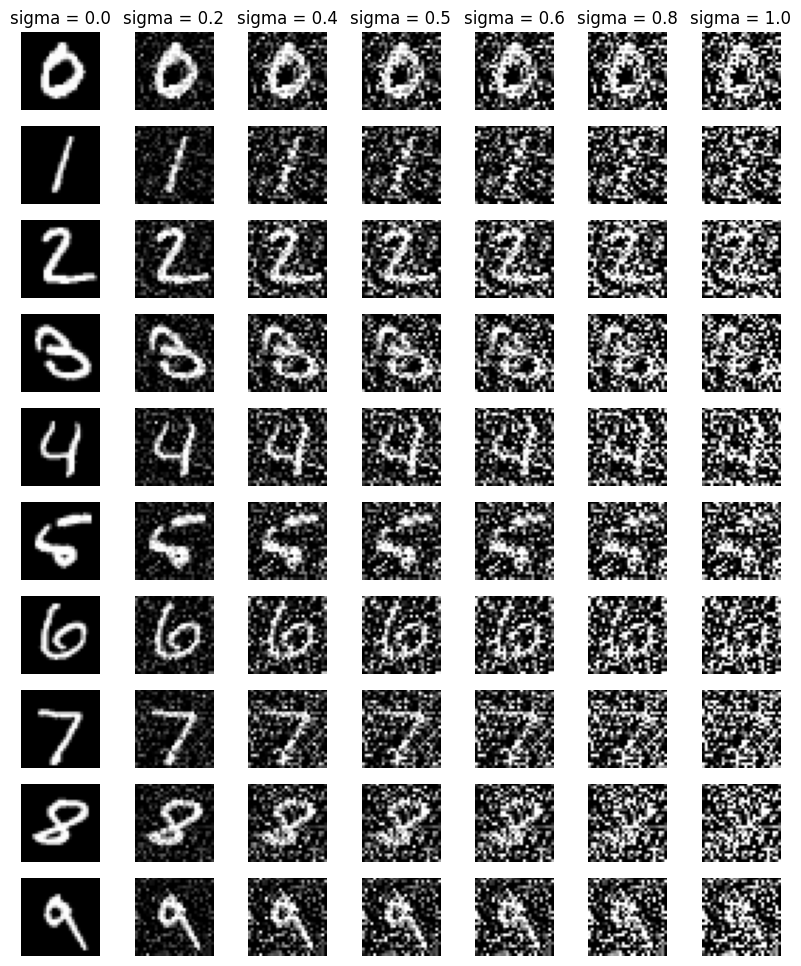

In [ ]:
# Visualize images at different noisy level
# ===== your code here! ====
examples = {}
for image, label in test_dataset:
    label = int(label)
    if label not in examples: examples[label] = image
    if len(examples) == 10: break

generator = torch.Generator()
generator.manual_seed(SEED + 1)

sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
fig, axes = plt.subplots(10, len(sigmas), figsize=(10, 12))

for digit in range(10):
    img = examples[digit]
    noise = torch.randn(img.shape, generator=generator)

    # reuse noise so each col shows only effect of changing sigma
    for col, sigma in enumerate(sigmas):
        noisy_image = img + sigma*noise

        # remove channel dim and clamp only for display
        display_image = noisy_image[0].clamp(0, 1)
        ax = axes[digit, col]
        ax.imshow(display_image, cmap='gray', vmin=0, vmax=1)
        ax.axis('off')

        if digit == 0: ax.set_title(f'sigma = {sigma:.1f}')

# ===== end of code ====

## Part 1.2.1: Training

For this part, we provide some structure code for training. It is very basic, so feel free to change them or add your code. In later section we won't provide any training or visualization structure code.

In [48]:
# Complete the recommended denoising hyperparameters from Section 1.2.1.
batch_size = 256
learning_rate = 1e-4
noise_level = 0.5
hidden_dim = 128
num_epochs = 5

In [49]:
# MNIST train_dataset/test_dataset were loaded in setup.
# Build shuffled training and non-shuffled test DataLoaders.
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [50]:
# Define your model, optimizer, and loss
# ===== your code here! ====
model = UnconditionalUNet(in_channels=1, num_hiddens=hidden_dim)
model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()
# ===== end of code ====

Epoch 1/5:   0%|          | 0/235 [00:00<?, ?it/s]

Finished epoch 1 of 5


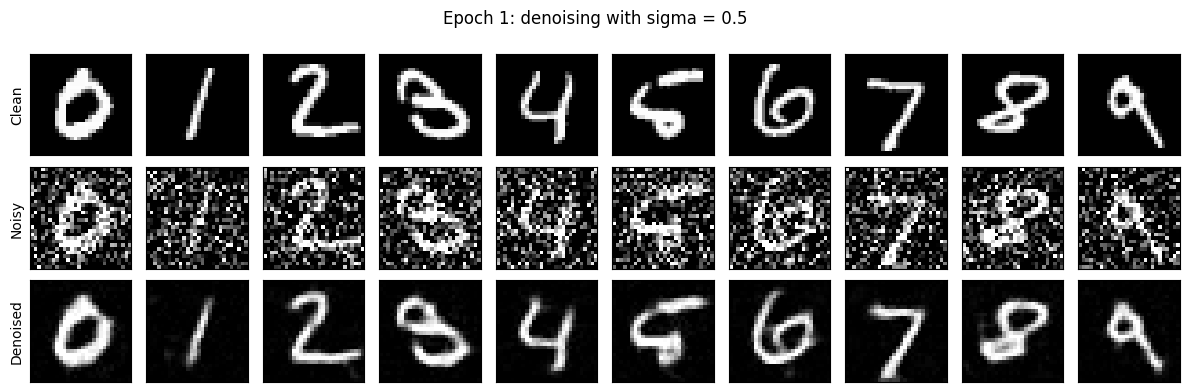

Epoch 2/5:   0%|          | 0/235 [00:00<?, ?it/s]

Finished epoch 2 of 5


Epoch 3/5:   0%|          | 0/235 [00:00<?, ?it/s]

Finished epoch 3 of 5


Epoch 4/5:   0%|          | 0/235 [00:00<?, ?it/s]

Finished epoch 4 of 5


Epoch 5/5:   0%|          | 0/235 [00:00<?, ?it/s]

Finished epoch 5 of 5


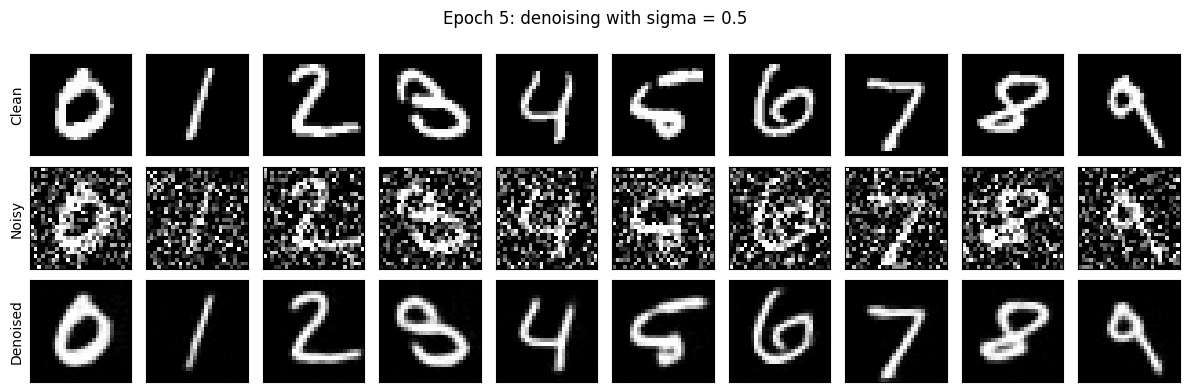

UnconditionalUNet(
  (conv): ConvBlock(
    (layers): Sequential(
      (0): Conv(
        (layers): Sequential(
          (0): Conv2d(1, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): GELU(approximate='none')
        )
      )
      (1): Conv(
        (layers): Sequential(
          (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): GELU(approximate='none')
        )
      )
    )
  )
  (down1): DownBlock(
    (layers): Sequential(
      (0): DownConv(
        (layers): Sequential(
          (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): GELU(approximate='none')
        )
      )
      (1): ConvBlock(


In [51]:
from tqdm.auto import tqdm

# The training loops
eval_images = []
for digit in range(10): eval_images.append(examples[digit])
eval_clean = torch.stack(eval_images)

eval_generator = torch.Generator()
eval_generator.manual_seed(SEED + 2)
eval_noise = torch.randn(eval_clean.shape, generator=eval_generator)
eval_noisy = eval_clean + noise_level * eval_noise
eval_noisy = eval_noisy.to(device)

train_losses = []
for epoch in range(num_epochs):
    model.train()
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs}"):
        # ===== your code here! ====
        images = images.to(device)
        noise = torch.randn_like(images)
        noisy_images = images + noise_level*noise
        outputs = model(noisy_images)
        # ===== end of code ====

        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    epoch_number = epoch + 1
    print(f'Finished epoch {epoch_number} of {num_epochs}')
    if epoch_number == 1 or epoch_number == 5:
        model.eval()
        with torch.no_grad(): denoised = model(eval_noisy)
        denoised = denoised.cpu()
        noisy_display = eval_noisy.cpu()

        fig, axes = plt.subplots(3, 10, figsize=(12, 4))
        plot_rows = [eval_clean, noisy_display, denoised]
        row_names = ['Clean', 'Noisy', 'Denoised']
        for row in range(3):
            for digit in range(10):
                image = plot_rows[row][digit][0]
                image = image.clamp(0, 1)
                ax = axes[row, digit]
                ax.imshow(image, cmap='gray', vmin=0, vmax=1)
                ax.set_xticks([])
                ax.set_yticks([])
                if digit == 0:
                    ax.set_ylabel(row_names[row])

        fig.suptitle(f'Epoch {epoch_number}: denoising with sigma = {noise_level}')
        fig.tight_layout()
        filename = f'1_2_1_denoising_epoch_{epoch_number}.png'
        fig.savefig(OUT / filename, dpi=150)
        plt.show()
        plt.close(fig)

        checkpoint = {
            'epoch': epoch_number,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_losses': train_losses,
            'hidden_dim': hidden_dim,
            'noise_level': noise_level,
            'batch_size': batch_size,
            'learning_rate': learning_rate,
            'seed': SEED,
        }
        filename = f'1_2_1_denoiser_epoch_{epoch_number}.pt'
        torch.save(checkpoint, OUT / filename)

model.eval()

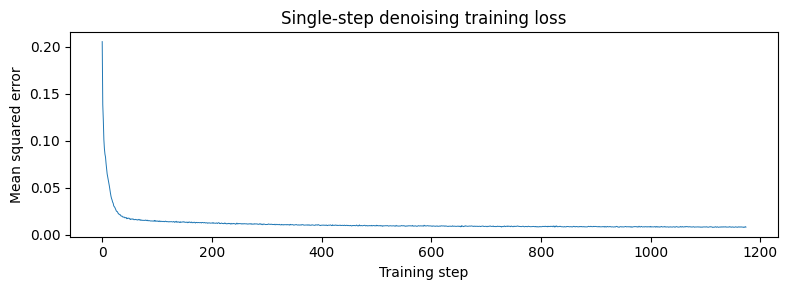

In [52]:
# Visualize your training curve
# ===== your code here! ====
plt.figure(figsize=(8, 3))
plt.plot(train_losses, linewidth=0.7)
plt.xlabel('Training step')
plt.ylabel('Mean squared error')
plt.title('Single-step denoising training loss')
plt.tight_layout()
plt.savefig(OUT / '1_2_1_denoising_loss.png', dpi=150)
plt.show()
plt.close()
# ===== end of code ====

## Part 1.2.2: Out-of-Distribution Testing

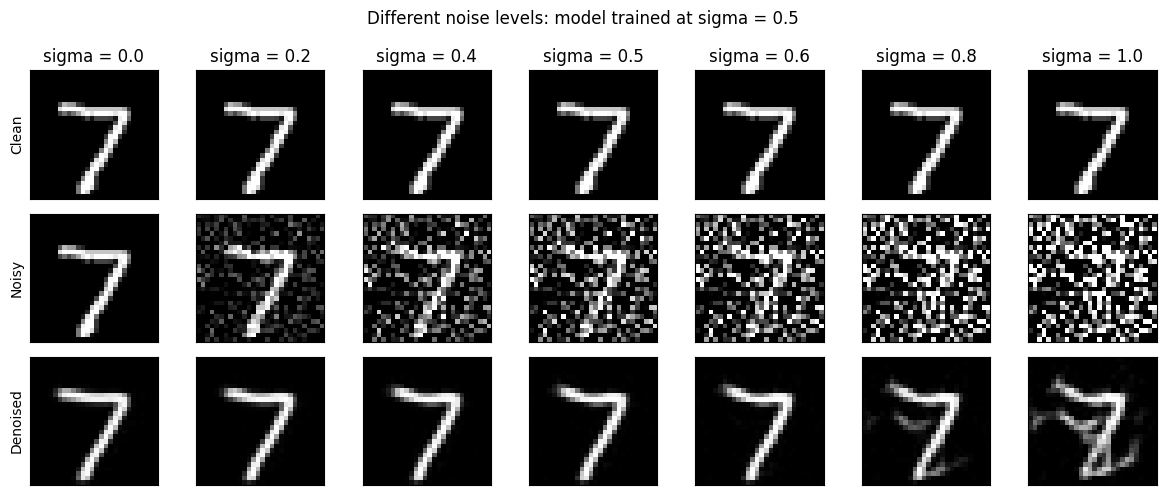

In [ ]:
# Visualize OOD testing
# ===== your code here! ====
model.eval()
sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]

clean_image = examples[7]
noise = torch.randn_like(clean_image)

fig, axes = plt.subplots(3, len(sigmas), figsize=(12, 5))
row_names = ['Clean', 'Noisy', 'Denoised']

for column, sigma in enumerate(sigmas):
    noisy_image = clean_image + sigma * noise

    model_input = noisy_image.unsqueeze(0)
    model_input = model_input.to(device)
    with torch.no_grad():
        prediction = model(model_input)
    denoised_image = prediction[0].cpu()

    plot_images = [clean_image, noisy_image, denoised_image]
    for row in range(3):
        display_image = plot_images[row][0].clamp(0, 1)
        ax = axes[row, column]
        ax.imshow(display_image, cmap='gray', vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if column == 0:
            ax.set_ylabel(row_names[row])

    axes[0, column].set_title(f'sigma = {sigma:.1f}')

fig.suptitle('Different noise levels: model trained at sigma = 0.5')
fig.tight_layout()
fig.savefig(OUT / '1_2_2_ood_denoising.png', dpi=150)
plt.show()
plt.close(fig)
# ===== end of code ====

## Part 1.2.3 Denoising Pure Noise

Pure noise: epoch 1/5:   0%|          | 0/235 [00:00<?, ?it/s]

Finished pure-noise epoch 1 of 5


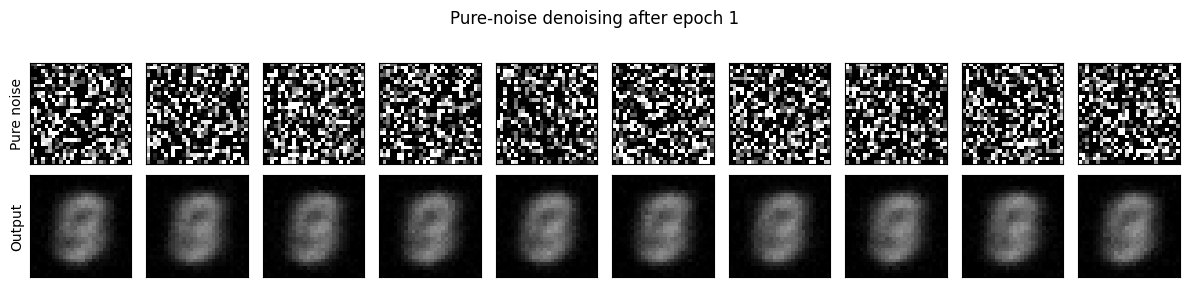

Pure noise: epoch 2/5:   0%|          | 0/235 [00:00<?, ?it/s]

Finished pure-noise epoch 2 of 5


Pure noise: epoch 3/5:   0%|          | 0/235 [00:00<?, ?it/s]

Finished pure-noise epoch 3 of 5


Pure noise: epoch 4/5:   0%|          | 0/235 [00:00<?, ?it/s]

Finished pure-noise epoch 4 of 5


Pure noise: epoch 5/5:   0%|          | 0/235 [00:00<?, ?it/s]

Finished pure-noise epoch 5 of 5


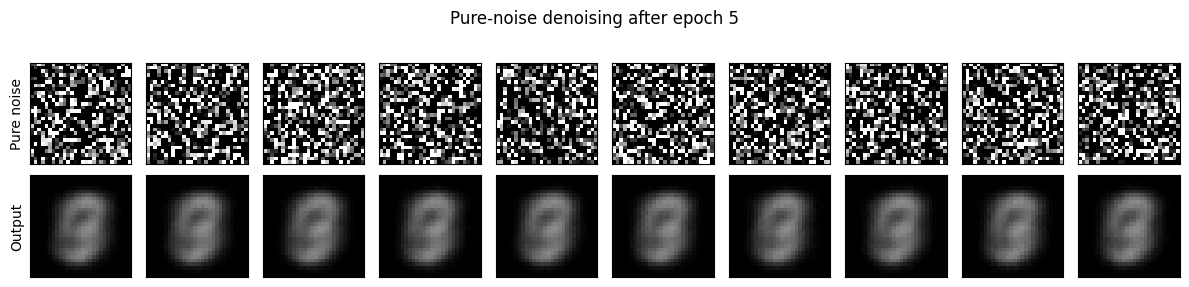

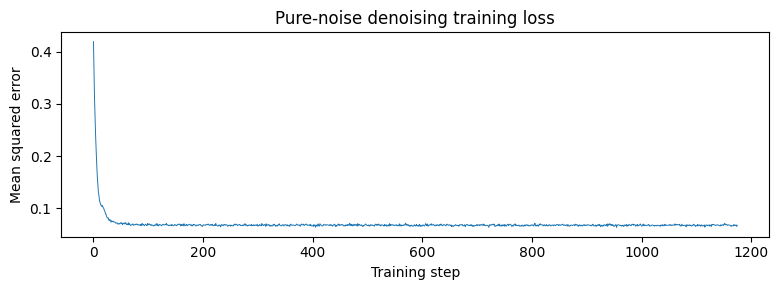

In [ ]:
# Section 1.2.3: train a fresh D=128 UNet for 5 epochs, Adam lr=1e-4,
# batch size 256. Input is independent Gaussian noise, target is a clean digit.
# Plot losses, show held-out results at epochs 1 and 5, and explain averaging.
from tqdm.auto import tqdm

pure_model = UnconditionalUNet(in_channels=1, num_hiddens=128)
pure_model = pure_model.to(device)
pure_optimizer = torch.optim.Adam(pure_model.parameters(), lr=1e-4)
pure_criterion = nn.MSELoss()
pure_train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
pure_num_epochs = 5

pure_generator = torch.Generator()
pure_generator.manual_seed(SEED + 3)
pure_test_noise = torch.randn(10, 1, 28, 28, generator=pure_generator)
pure_test_noise = pure_test_noise.to(device)

pure_train_losses = []
for epoch in range(pure_num_epochs):
    pure_model.train()
    for images, labels in tqdm(pure_train_loader, desc=f"Pure noise: epoch {epoch + 1}/{pure_num_epochs}"):
        images = images.to(device)

        noise = torch.randn_like(images)
        outputs = pure_model(noise)
        loss = pure_criterion(outputs, images)

        pure_optimizer.zero_grad()
        loss.backward()
        pure_optimizer.step()
        pure_train_losses.append(loss.item())

    epoch_number = epoch + 1
    print(f'Finished pure-noise epoch {epoch_number} of {pure_num_epochs}')

    if epoch_number == 1 or epoch_number == 5:
        pure_model.eval()
        with torch.no_grad():
            pure_predictions = pure_model(pure_test_noise)
        pure_predictions = pure_predictions.cpu()
        noise_display = pure_test_noise.cpu()

        fig, axes = plt.subplots(2, 10, figsize=(12, 3))
        plot_rows = [noise_display, pure_predictions]
        row_names = ['Pure noise', 'Output']
        for row in range(2):
            for column in range(10):
                image = plot_rows[row][column][0]
                image = image.clamp(0, 1)
                ax = axes[row, column]
                ax.imshow(image, cmap='gray', vmin=0, vmax=1)
                ax.set_xticks([])
                ax.set_yticks([])
                if column == 0:
                    ax.set_ylabel(row_names[row])

        fig.suptitle(f'Pure-noise denoising after epoch {epoch_number}')
        fig.tight_layout()
        filename = f'1_2_3_pure_noise_epoch_{epoch_number}.png'
        fig.savefig(OUT / filename, dpi=150)
        plt.show()
        plt.close(fig)

        pure_checkpoint = {
            'epoch': epoch_number,
            'model_state_dict': pure_model.state_dict(),
            'optimizer_state_dict': pure_optimizer.state_dict(),
            'train_losses': pure_train_losses,
            'hidden_dim': 128,
            'batch_size': 256,
            'learning_rate': 1e-4,
        }
        filename = f'1_2_3_pure_noise_epoch_{epoch_number}.pt'
        torch.save(pure_checkpoint, OUT / filename)

pure_model.eval()

plt.figure(figsize=(8, 3))
plt.plot(pure_train_losses, linewidth=0.7)
plt.xlabel('Training step')
plt.ylabel('Mean squared error')
plt.title('Pure-noise denoising training loss')
plt.tight_layout()
plt.savefig(OUT / '1_2_3_pure_noise_loss.png', dpi=150)
plt.show()
plt.close()

# Part 2: Flow Matching

# Part 2.1: Implementing a Time-conditioned UNet

In [64]:
class FCBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.linear1 = nn.Linear(in_channels, out_channels)
        self.activation = nn.GELU()
        self.linear2 = nn.Linear(out_channels, out_channels)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        x = self.linear1(x)
        x = self.activation(x)
        x = self.linear2(x)
        return x
        # ===== end of code ====


class TimeConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        D = num_hiddens

        self.conv = ConvBlock(in_channels, D)
        self.down1, self.down2 = DownBlock(D, D), DownBlock(D, 2 * D)
        self.flatten, self.unflatten = Flatten(), Unflatten(2 * D)
        self.up1, self.up2 = UpBlock(4 * D, D), UpBlock(2 * D, D)
        self.out_block = ConvBlock(2 * D, D)
        self.out = nn.Conv2d(D, in_channels, 3, stride=1, padding=1)

        # embed time, use it to scale the decoder feature maps
        self.fc1_t, self.fc2_t = FCBlock(1, 2 * D), FCBlock(1, D)
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        t: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            t: (N,) normalized time tensor.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        t = t.reshape(-1, 1)
        s0 = self.conv(x)
        s1 = self.down1(s0)
        s2 = self.down2(s1)

        h = self.unflatten(self.flatten(s2))

        tf = self.fc1_t(t).reshape(x.shape[0], -1, 1, 1)
        h = h * tf
        
        h = torch.cat([h, s2], dim=1)
        h = self.up1(h)

        tf = self.fc2_t(t).reshape(x.shape[0], -1, 1, 1)
        h = h * tf

        h = torch.cat([h, s1], dim=1)
        h = self.up2(h)
        h = torch.cat([h, s0], dim=1)
        h = self.out_block(h)
        output = self.out(h)
        return output
        # ===== end of code ====

## Implementing the Forward and Reverse Process for Time-conditioned Denoising

In [65]:
def time_fm_forward(
    unet: TimeConditionalUNet,
    x_1: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 1

    Args:
        unet: TimeConditionalUNet
        x_1: (N, C, H, W) input tensor.
        num_ts: int, number of timesteps.
    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    x_0 = torch.randn_like(x_1)
    bs = x_1.shape[0]
    t = torch.rand(bs, device=x_1.device)

    t_for_images = t.reshape(bs, 1, 1, 1)
    x_t = (1-t_for_images)*x_0 + t_for_images*x_1

    target_velocity = x_1 - x_0
    predicted_velocity = unet(x_t, t)
    loss = F.mse_loss(predicted_velocity, target_velocity)
    return loss
    # ===== end of code ====

In [67]:
@torch.inference_mode()
def time_fm_sample(
    unet: TimeConditionalUNet,
    img_wh: tuple[int, int],
    num_ts: int,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 2

    Args:
        unet: TimeConditionalUNet
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
    """
    unet.eval()
    # ===== your code here! ====
    device = next(unet.parameters()).device
    h, w = img_wh
    generator = torch.Generator(device=device)
    generator.manual_seed(seed)
    x_t = torch.randn(1, 1, h, w, generator=generator, device=device)

    step_size = 1.0 / num_ts
    for step in range(num_ts):
        current_time = step / num_ts
        t = torch.full((x_t.shape[0],), current_time, device=device)
        velocity = unet(x_t, t)
        x_t = x_t + step_size * velocity

    return x_t
    # ===== end of code ====

In [68]:
class TimeConditionalFM(nn.Module):
    def __init__(
        self,
        unet: TimeConditionalUNet,
        num_ts: int = 50,
        img_hw: tuple[int, int] = (28, 28),
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.img_hw = img_hw


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) flow-matching loss.
        """
        return time_fm_forward(
            self.unet, x, self.num_ts
        )


    @torch.inference_mode()
    def sample(
        self,
        img_wh: tuple[int, int],
        seed: int = 0,
    ):
        return time_fm_sample(
            self.unet, img_wh, self.num_ts, seed
        )

# Part 2.2: Training the Time-conditioned UNet

Time model: epoch 1/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 1: mean batch loss = 0.189060


Time model: epoch 2/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 2: mean batch loss = 0.125019


Time model: epoch 3/10:   0%|          | 0/938 [00:00<?, ?it/s]

...

Epoch 8: mean batch loss = 0.096127


Time model: epoch 9/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 9: mean batch loss = 0.094902


Time model: epoch 10/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 10: mean batch loss = 0.093397


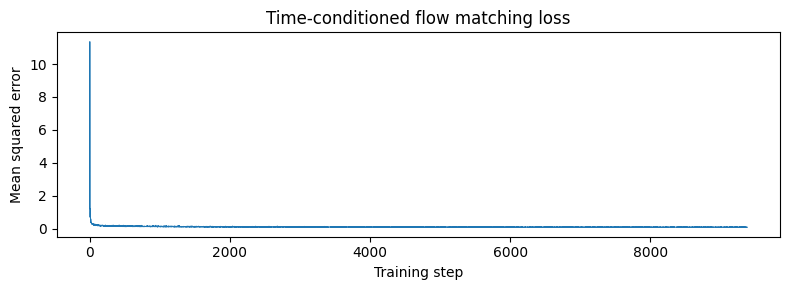

In [69]:
# Feel free to use code from part 1.2.1
# as they should be very similar
# ===== your code here! ====
t_nepochs = 10
t_bs = 64
t_lr = 1e-2
t_hdim = 64
t_nsteps = 50

t_loader = DataLoader(train_dataset, batch_size=t_bs, shuffle=True)
t_unet = TimeConditionalUNet(in_channels=1, num_classes=10, num_hiddens=t_hdim)
t_unet = t_unet.to(device)
t_model = TimeConditionalFM(t_unet, num_ts=t_nsteps)
t_optimizer = torch.optim.Adam(t_unet.parameters(), lr=t_lr)

gamma = 0.1 ** (1.0 / t_nepochs)
t_scheduler = torch.optim.lr_scheduler.ExponentialLR(t_optimizer, gamma=gamma)

t_losses = []
t_checkpoints = {}
for epoch in range(t_nepochs):
    t_unet.train()
    total_loss = 0
    num_batches = 0

    for images, labels in tqdm(
        t_loader, desc=f"Time model: epoch {epoch + 1}/{t_nepochs}"):
        images = images.to(device)
        loss = t_model(images)

        t_optimizer.zero_grad()
        loss.backward()
        t_optimizer.step()

        t_losses.append(loss.item())
        total_loss += loss.item()
        num_batches += 1

    t_scheduler.step()
    epoch_number = epoch + 1
    average_loss = total_loss / num_batches
    print(f'Epoch {epoch_number}: mean batch loss = {average_loss:.6f}')

    # save weights at epochs used for the sampling comp
    if epoch_number==1 or epoch_number==5 or epoch_number==10:
        checkpoint = {
            'epoch': epoch_number,
            'model_state_dict': t_unet.state_dict(),
            'optimizer_state_dict': t_optimizer.state_dict(),
            'train_losses': t_losses,
            'hidden_dim': t_hdim,
            'learning_rate': t_lr,
            'batch_size': t_bs,
            'num_timesteps': t_nsteps,
        }
        filename = f'2_2_t_model_epoch_{epoch_number}.pt'
        torch.save(checkpoint, OUT / filename)
        t_checkpoints[epoch_number] = checkpoint

# Plot the loss from every optimizer step.
plt.figure(figsize=(8, 3))
plt.plot(t_losses, linewidth=0.7)
plt.xlabel('Training step')
plt.ylabel('Mean squared error')
plt.title('Time-conditioned flow matching loss')
plt.tight_layout()
plt.savefig(OUT / '2_2_time_training_loss.png', dpi=150)
plt.show()
plt.close()
# ===== end of code ====

# Part 2.3: Sampling from the Time-conditioned UNet

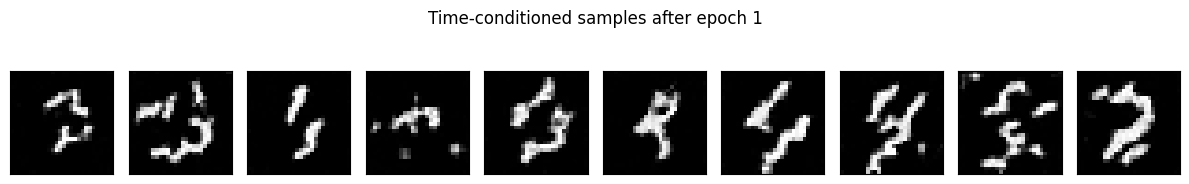

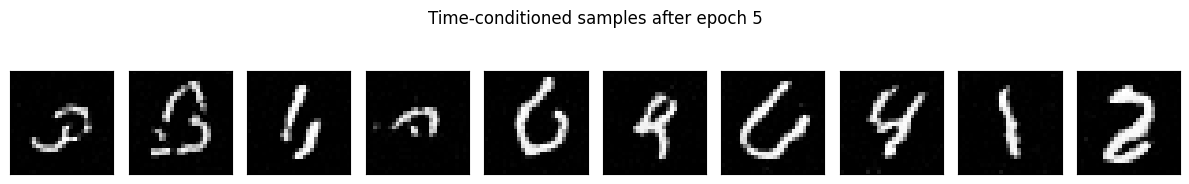

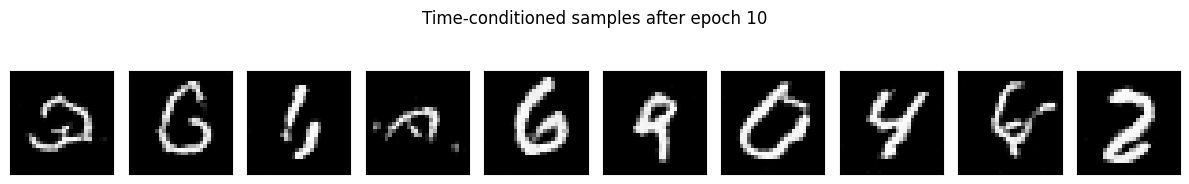

TimeConditionalUNet(
  (conv): ConvBlock(
    (layers): Sequential(
      (0): Conv(
        (layers): Sequential(
          (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): GELU(approximate='none')
        )
      )
      (1): Conv(
        (layers): Sequential(
          (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): GELU(approximate='none')
        )
      )
    )
  )
  (down1): DownBlock(
    (layers): Sequential(
      (0): DownConv(
        (layers): Sequential(
          (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): GELU(approximate='none')
        )
      )
      (1): ConvBlock(
      

In [70]:
# Sampling from the UNet
# ===== your code here! ====
for epoch_number in [1, 5, 10]:
    checkpoint = torch.load(
        OUT / f'2_2_t_model_epoch_{epoch_number}.pt',
        map_location=device,
        weights_only=True,
    )
    t_unet.load_state_dict(checkpoint['model_state_dict'])
    t_unet.eval()

    # gen 10 examples using a diff seed for each one
    samples = []
    for seed in range(10):
        sample = t_model.sample((28, 28), seed=seed)
        samples.append(sample[0].cpu())
    samples = torch.stack(samples)

    fig, axes = plt.subplots(1, 10, figsize=(12, 2))
    for column in range(10):
        image = samples[column][0].clamp(0, 1)
        axes[column].imshow(image, cmap='gray', vmin=0, vmax=1)
        axes[column].set_xticks([])
        axes[column].set_yticks([])

    fig.suptitle(f'Time-conditioned samples after epoch {epoch_number}')
    fig.tight_layout()
    filename = f'2_3_t_samples_epoch_{epoch_number}.png'
    fig.savefig(OUT / filename, dpi=150)
    plt.show()
    plt.close(fig)

t_unet.load_state_dict(t_checkpoints[10]['model_state_dict'])
t_unet.eval()
# ===== end of code ====

# Part 2.4: Implementing a Class-conditioned UNet

In [ ]:
class ClassConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        D = num_hiddens

        self.conv = ConvBlock(in_channels, D)
        self.down1, self.down2 = DownBlock(D, D), DownBlock(D, 2 * D)
        self.flatten, self.unflatten = Flatten(), Unflatten(2 * D)
        self.up1, self.up2 = UpBlock(4 * D, D), UpBlock(2 * D, D)
        self.out_block = ConvBlock(2 * D, D)
        self.out = nn.Conv2d(D, in_channels, 3, stride=1, padding=1)

        self.fc1_t, self.fc1_c = FCBlock(1, 2 * D), FCBlock(num_classes, 2 * D)
        self.fc2_t, self.fc2_c = FCBlock(1, D), FCBlock(num_classes, D)
        self.num_classes = num_classes
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.
            t: (N,) normalized time tensor.
            mask: (N,) mask tensor. If not None, mask out condition when mask == 0.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        bs = x.shape[0]
        t = t.reshape(bs, 1)

        c = F.one_hot(c.long(), num_classes=self.num_classes).float().to(x.device)

        if mask is not None:
            mask = mask.reshape(bs, 1).to(x.device)
            c *= mask

        s0 = self.conv(x)
        s1 = self.down1(s0)
        s2 = self.down2(s1)

        h = self.unflatten(self.flatten(s2))
        tf = self.fc1_t(t).reshape(bs, -1, 1, 1)
        cf = self.fc1_c(c).reshape(bs, -1, 1, 1)
        h = cf*h + tf

        h = torch.cat([h, s2], dim=1)
        h = self.up1(h)
        tf = self.fc2_t(t).reshape(bs, -1, 1, 1)
        cf = self.fc2_c(c).reshape(bs, -1, 1, 1)
        h = cf*h + tf

        h = torch.cat([h, s1], dim=1)
        h = self.up2(h)
        h = torch.cat([h, s0], dim=1)
        h = self.out_block(h)
        output = self.out(h)
        return output
        # ===== end of code ====

In [75]:
def class_fm_forward(
    unet: ClassConditionalUNet,
    x_1: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 3

    Args:
        unet: ClassConditionalUNet
        x_1: (N, C, H, W) input tensor.
        c: (N,) int64 condition tensor.
        p_uncond: float, probability of unconditioning the condition.
        num_ts: int, number of timesteps.

    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    bs = x_1.shape[0]
    device = x_1.device

    # rand remove the class cond from some training examples
    mask = torch.ones(bs, device=device)
    drop_cond = torch.rand(bs, device=device) < p_uncond
    mask[drop_cond] = 0

    # sel a random time and a random noise image for each
    t = torch.rand(bs, device=device)
    x_0 = torch.randn_like(x_1)

    # make intermediate img between noise and clean img
    t_for_images = t.reshape(bs, 1, 1, 1)
    x_t = (1-t_for_images)*x_0 + t_for_images*x_1

    # predict velocity that moves the noise toward the clean image
    target_velocity = x_1 - x_0
    predicted_velocity = unet(x_t, c, t, mask)
    loss = F.mse_loss(predicted_velocity, target_velocity)
    return loss
    # ===== end of code ====

In [ ]:
@torch.inference_mode()
def class_fm_sample(
    unet: ClassConditionalUNet,
    c: torch.Tensor,
    img_wh: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 4

    Args:
        unet: ClassConditionalUNet
        c: (N,) int64 condition tensor. Only for class-conditional
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        guidance_scale: float, CFG scale.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
        (N, T_animation, C, H, W) caches.
    """
    unet.eval()
    # ===== your code here! ====
    device = next(unet.parameters()).device
    c = c.to(device).long()

    h, w = img_wh
    generator = torch.Generator(device=device)
    generator.manual_seed(seed)
    x_t = torch.randn(len(c), 1, h, w, generator=generator, device=device)

    step_size = 1.0 / num_ts
    for step in range(num_ts):
        current_time = step / num_ts
        t = torch.full((len(c),), current_time, device=device)

        no_class_mask = torch.zeros(len(c), device=device)
        uncond_velocity = unet(x_t, c, t, no_class_mask)
        cond_velocity = unet(x_t, c, t)

        velocity = uncond_velocity + guidance_scale*(cond_velocity-uncond_velocity)
        x_t += step_size*velocity

    return x_t
    # ===== end of code ====

In [77]:
class ClassConditionalFM(nn.Module):
    def __init__(
        self,
        unet: ClassConditionalUNet,
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self.num_ts = num_ts
        self.p_uncond = p_uncond

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.

        Returns:
            (,) loss.
        """
        return class_fm_forward(
            self.unet, x, c, self.p_uncond, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_wh: tuple[int, int],
        guidance_scale: float = 5.0,
        seed: int = 0,
    ):
        return class_fm_sample(
            self.unet, c, img_wh, self.num_ts, guidance_scale, seed
        )

# Part 2.5 Training the Class-conditioned UNet

2_5_class: epoch 1/10:   0%|          | 0/938 [00:00<?, ?it/s]

2_5_class, epoch 1: loss = 0.180408


2_5_class: epoch 2/10:   0%|          | 0/938 [00:00<?, ?it/s]

2_5_class, epoch 2: loss = 0.116320


2_5_class: epoch 3/10:   0%|          | 0/938 [00:00<?, ?it/s]

...

2_5_class_no_scheduler, epoch 8: loss = 0.086583


2_5_class_no_scheduler: epoch 9/10:   0%|          | 0/938 [00:00<?, ?it/s]

2_5_class_no_scheduler, epoch 9: loss = 0.086470


2_5_class_no_scheduler: epoch 10/10:   0%|          | 0/938 [00:00<?, ?it/s]

2_5_class_no_scheduler, epoch 10: loss = 0.085093


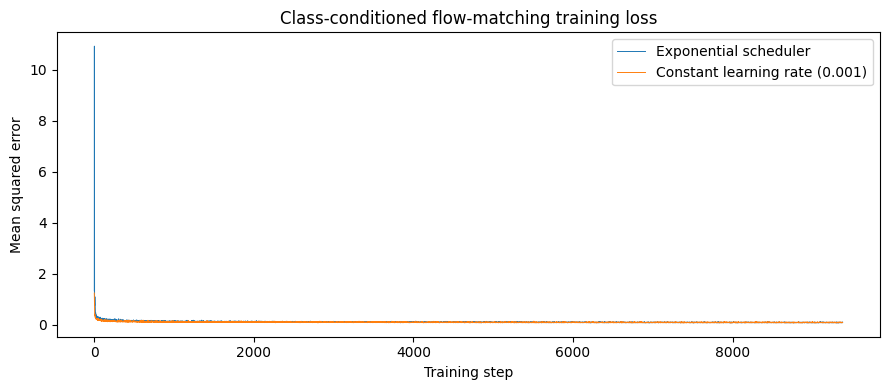

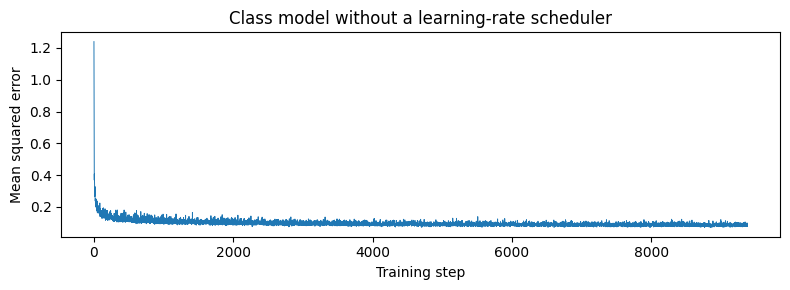

In [ ]:
# Train a fresh class-conditioned D=64 UNet for 10 epochs, batch size 64,
# Adam initial lr=1e-2, class dropout probability .1, exponential gamma=.1**(1/10).
# Save checkpoints at epochs 1,5,10. Then train an independent no-scheduler
# comparison; choose/document a constant learning rate and compare results.
from tqdm.auto import tqdm

# Settings from the assignment.
c_epochs = 10
c_bs = 64
c_lr = 1e-2
c_hdim = 64
c_steps = 300
c_drop_prob = 0.1

c_train_loader = DataLoader(train_dataset, batch_size=c_bs, shuffle=True)

def train_class_model(model, learning_rate, use_scheduler, save_name):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    if use_scheduler:
        gamma = 0.1 ** (1.0 / c_epochs)
        scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=gamma)
    else: scheduler = None

    flow_model = ClassConditionalFM(model, num_ts=c_steps, p_uncond=c_drop_prob)
    losses, checkpoints = [], {}

    for epoch in range(c_epochs):
        model.train()
        total_loss, num_batches = 0, 0

        for images, labels in tqdm(
            c_train_loader,
            desc=f'{save_name}: epoch {epoch + 1}/{c_epochs}'
        ):
            images, labels = images.to(device), labels.to(device)

            loss = flow_model(images, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            losses.append(loss.item())
            total_loss += loss.item()
            num_batches += 1

        if scheduler is not None: scheduler.step()

        epoch_num = epoch + 1
        average_loss = total_loss / num_batches
        print(f'{save_name}, epoch {epoch_num}: loss = {average_loss:.6f}')

        if epoch_num==1 or epoch_num==5 or epoch_num==10:
            checkpoint = {
                'epoch': epoch_num,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'losses': losses,
                'hidden_dim': c_hdim,
                'batch_size': c_bs,
                'learning_rate': learning_rate,
                'p_uncond': c_drop_prob,
                'num_timesteps': c_steps,
                'use_scheduler': use_scheduler
            }
            filename = f'{save_name}_epoch_{epoch_num}.pt'
            torch.save(checkpoint, OUT / filename)
            checkpoints[epoch_num] = checkpoint

    return losses, checkpoints


# MAIN EXP: Adam with recommended exponential LR decay
c_unet = ClassConditionalUNet(in_channels=1, num_classes=10, num_hiddens=c_hdim)
c_unet = c_unet.to(device)
c_losses, c_checkpoints = train_class_model(c_unet, c_lr, use_scheduler=True, save_name='2_5_class')

# Comparison experiment: independent model with a constant LR
# 0.001 matches the scheduler's LR at the end of the 10 epochs
c_constant_lr = 1e-3
c_nosched_unet = ClassConditionalUNet(in_channels=1, num_classes=10, num_hiddens=c_hdim)
c_nosched_unet = c_nosched_unet.to(device)
c_nosched_losses, c_nosched_checkpoints = train_class_model(c_nosched_unet, c_constant_lr, use_scheduler=False, save_name='2_5_class_no_scheduler')

# plot losses from both experiments.
plt.figure(figsize=(9, 4))
plt.plot(c_losses, label='Exponential scheduler', linewidth=0.7)
plt.plot(c_nosched_losses, label='Constant learning rate (0.001)', linewidth=0.7)
plt.xlabel('Training step')
plt.ylabel('Mean squared error')
plt.title('Class-conditioned flow-matching training loss')
plt.legend()
plt.tight_layout()
plt.savefig(OUT / '2_5_class_training_loss.png', dpi=150)
plt.show()
plt.close()

# save the constant-LR experiment separately
plt.figure(figsize=(8, 3))
plt.plot(c_nosched_losses, linewidth=0.7)
plt.xlabel('Training step')
plt.ylabel('Mean squared error')
plt.title('Class model without a learning-rate scheduler')
plt.tight_layout()
plt.savefig(OUT / '2_5_class_no_scheduler_loss.png', dpi=150)
plt.show()
plt.close()

# Part 2.6: Sampling from the Class-conditioned UNet

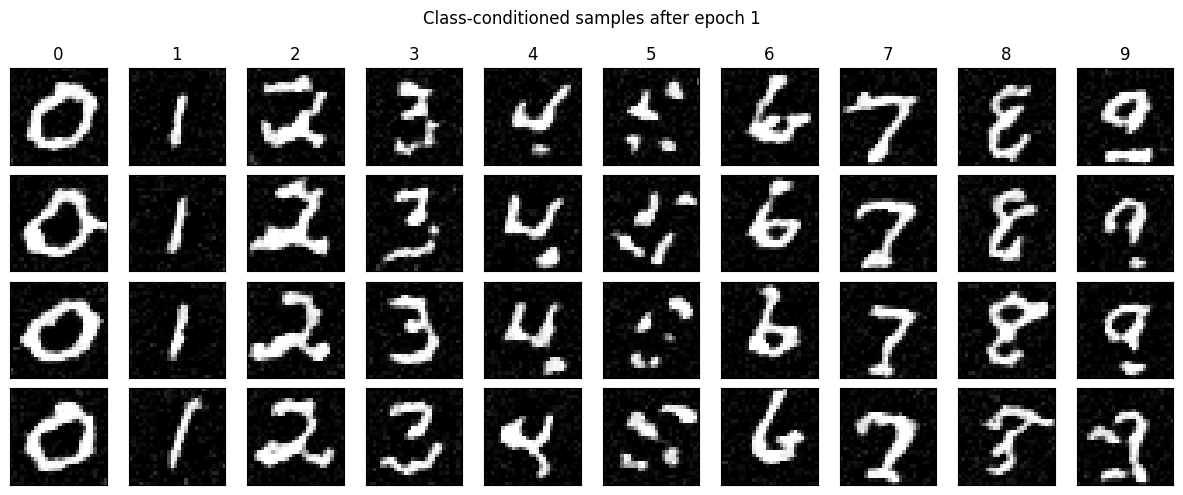

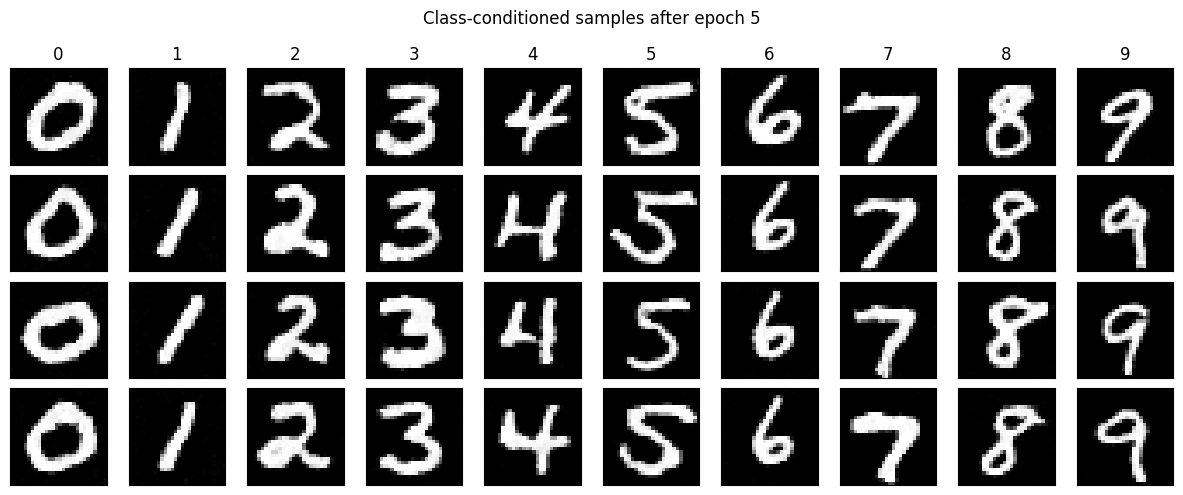

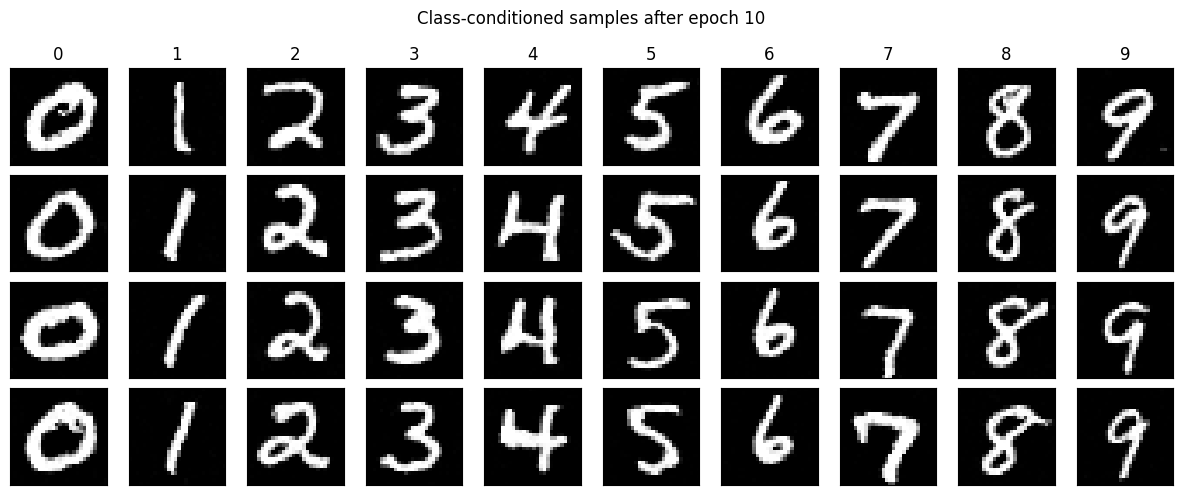

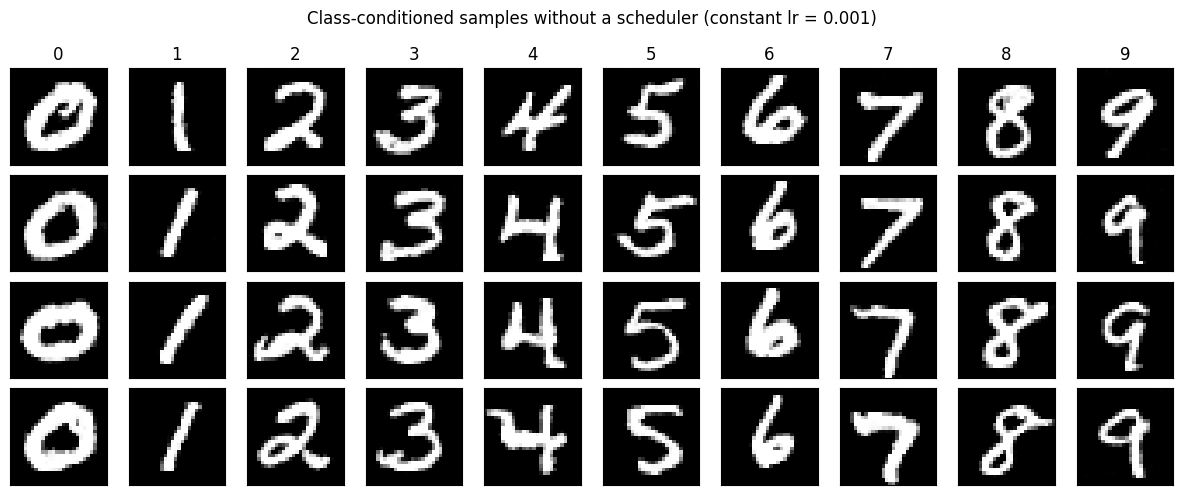

In [ ]:
# At epochs 1,5,10, generate four instances of each digit (40 images),
# with 300 Euler steps and guidance scale 5.0. Keep seeds fixed for comparisons.
# Also visualize the no-scheduler model and describe the tradeoff.
# Make four samples of each digit. Each row contains one sample of every digit.
class_labels = torch.arange(10, device=device).repeat(4)

def plot_class_samples(model, title, filename):
    model.eval()

    samples = model.sample(
        class_labels,
        (28, 28),
        guidance_scale=5.0,
        seed=2026,
    )
    samples = samples.cpu()

    fig, axes = plt.subplots(4, 10, figsize=(12, 5))
    for row in range(4):
        for dig in range(10):
            image_index = row * 10 + dig
            img = samples[image_index][0].clamp(0, 1)
            axes[row, dig].imshow(img, cmap='gray', vmin=0, vmax=1)
            axes[row, dig].set_xticks([])
            axes[row, dig].set_yticks([])
            if row == 0: axes[row, dig].set_title(str(dig))

    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=150)
    plt.show()
    plt.close(fig)


c_fm_model = ClassConditionalFM(c_unet, num_ts=300, p_uncond=c_drop_prob)
for epoch_number in [1, 5, 10]:
    checkpoint = torch.load(
        OUT / f'2_5_class_epoch_{epoch_number}.pt',
        map_location=device
    )
    c_unet.load_state_dict(checkpoint['model_state_dict'])
    plot_class_samples(
        c_fm_model,
        f'Class-conditioned samples after epoch {epoch_number}',
        f'2_6_class_samples_epoch_{epoch_number}.png'
    )

c_nosched_fm_model = ClassConditionalFM(c_nosched_unet, num_ts=300, p_uncond=c_drop_prob)
checkpoint = torch.load(
    OUT / '2_5_class_no_scheduler_epoch_10.pt',
    map_location=device
)
c_nosched_unet.load_state_dict(checkpoint['model_state_dict'])
plot_class_samples(
    c_nosched_fm_model,
    'Class-conditioned samples without a scheduler (constant lr = 0.001)',
    '2_6_class_samples_no_scheduler.png'
)